PROTON/PION - Calibration step

Step 1 - Calibration: Scaling & summing up energy


In [1]:
#Reading the files

import os
# os.chdir('C:/Users/Sofia/Desktop/High energy physics thesis')
os.chdir('..')

import robi.core
import numpy as np
import pandas as pd
import math
from mpl_toolkits.mplot3d import Axes3D #for 3D projection

#proton

input_standalone_proton_s1_csv = 'data/simulations/regression-proton/proton_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv'
input_standalone_proton_s2_csv = 'data/simulations/regression-proton/proton_standalone_N100000_M0_20GeV_reg_balanced_s2_v3.csv'

df_standalone_proton_s1 = robi.core.pd.read_csv(input_standalone_proton_s1_csv)
print("Number of hits in Proton Standalone Seed 1: ", len(df_standalone_proton_s1))

df_standalone_proton_s2 = robi.core.pd.read_csv(input_standalone_proton_s2_csv)
print("Number of hits in Proton Standalone Seed 2: ", len(df_standalone_proton_s2))

df_standalone_proton_s1 = robi.core.shifted_z(df_standalone_proton_s1)
print("Range of Coordinate of Z in Proton Standalone Seed 1:", round(df_standalone_proton_s1["z"].min(), 2), round(df_standalone_proton_s1["z"].max(), 2))

df_standalone_proton_s2 = robi.core.shifted_z(df_standalone_proton_s2)
print("Range of Coordinate of Z in Proton Standalone Seed 2:", round(df_standalone_proton_s2["z"].min(), 2), round(df_standalone_proton_s2["z"].max(), 2))

#pion

input_standalone_pion_s1_csv = 'data/simulations/regression-pion/pion_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv'
input_standalone_pion_s2_csv = 'data/simulations/regression-pion/pion_standalone_N100000_M0_20GeV_reg_balanced_s2_v3.csv'

df_standalone_pion_s1 = robi.core.pd.read_csv(input_standalone_pion_s1_csv)
print("Number of hits in Pion Standalone Seed 1: ", len(df_standalone_pion_s1))

df_standalone_pion_s2 = robi.core.pd.read_csv(input_standalone_pion_s2_csv)
print("Number of hits in Pion Standalone Seed 2: ", len(df_standalone_pion_s2))

df_standalone_pion_s1 = robi.core.shifted_z(df_standalone_pion_s1)
print("Range of Coordinate of Z in Pion Standalone Seed 1:", round(df_standalone_pion_s1["z"].min(), 2), round(df_standalone_pion_s1["z"].max(), 2))

df_standalone_pion_s2 = robi.core.shifted_z(df_standalone_pion_s2)
print("Range of Coordinate of Z in Pion Standalone Seed 2:", round(df_standalone_pion_s2["z"].min(), 2), round(df_standalone_pion_s2["z"].max(), 2))


2026-10-09 13:02:58.828562: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-09 13:02:58.879286: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-09 13:02:59.827194: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Number of hits in Proton Standalone Seed 1:  54740548
Number of hits in Proton Standalone Seed 2:  54822842
Range of Coordinate of Z in Proton Standalone Seed 1: 13.4 1222.9
Range of Coordinate of Z in Proton Standalone Seed 2: 13.4 1222.9
Number of hits in Pion Standalone Seed 1:  49110973
Number of hits in Pion Standalone Seed 2:  48965087
Range of Coordinate of Z in Pion Standalone Seed 1: 13.4 1222.9
Range of Coordinate of Z in Pion Standalone Seed 2: 13.4 1222.9


Percentage of visible energy calculation, adding up all energy deposits, divide every single event's total deposited energy by event's incoming momentum to get scaling factor

For sampling fraction: divide the mean of the Gaussian by visible incoming energy

In [2]:
#@ sampling fraction (calibration) per event

def compute_sampling_fraction(df):
    """
    One row per event: total deposited energy in that event, divided by the
    particle's true incoming momentum. This ratio is the 'sampling fraction' -
    how much of the true energy the calorimeter actually sees.
    """
    event_totals = df.groupby('event_number').agg(
        visible_energy=('energy', 'sum'),
        incoming_momentum=('incoming_momentum', 'first'),
    ).reset_index()
    event_totals['sampling_fraction'] = event_totals['visible_energy'] / event_totals['incoming_momentum']
    return event_totals

Getting the mean of the Gaussian, calculating scaling factor

In [3]:
#Gaussian dist and Gaussian mean calculation

def plot_sampling_fraction_distribution(df, particle_label, low_cut=None, high_cut=None):
    event_totals = compute_sampling_fraction(df)

    if low_cut is not None:
        event_totals = event_totals[event_totals['incoming_momentum'] >= low_cut]
    if high_cut is not None:
        event_totals = event_totals[event_totals['incoming_momentum'] < high_cut]

    mean_sf = event_totals['sampling_fraction'].mean()
    std_sf = event_totals['sampling_fraction'].std()
    scaling_factor = 1.0 / mean_sf

    fig, ax = robi.core.plt.subplots(figsize=(7, 5))
    ax.hist(event_totals['sampling_fraction'] * 100, bins=50, color='steelblue', alpha=0.8)
    ax.axvline(mean_sf * 100, color='firebrick', linestyle='--', label=f'mean = {mean_sf*100:.3f}%')
    ax.set_xlabel('Sampling fraction (%)')
    ax.set_ylabel('Events')
    label_range = f" [{low_cut}-{high_cut} GeV]" if low_cut is not None else " (all momenta)"
    ax.set_title(f'{particle_label}: sampling fraction distribution{label_range}')
    ax.legend()
    robi.core.plt.tight_layout()
    robi.core.plt.show()

    print(f"{particle_label}{label_range}: mean sampling fraction = {mean_sf*100:.4f}%, "
          f"std = {std_sf*100:.4f}%, n_events = {len(event_totals)}")
    print(f"{particle_label}{label_range}: scaling factor (1 / sampling fraction) = {scaling_factor:.4f}")
    return mean_sf, scaling_factor

Sampling fraction

In [4]:
def sampling_fraction_vs_momentum(df, particle_label, bin_width=1.0, momentum_max=20.0):
    event_totals = compute_sampling_fraction(df)

    bins = np.arange(0, momentum_max + bin_width, bin_width)
    event_totals['momentum_bin'] = pd.cut(event_totals['incoming_momentum'], bins=bins)

    summary = (event_totals.groupby('momentum_bin', observed=True)['sampling_fraction']
               .agg(['mean', 'std', 'count']).reset_index())
    summary['bin_center'] = summary['momentum_bin'].apply(lambda b: b.mid)
    summary['scaling_factor'] = 1.0 / summary['mean']

    fig, ax = robi.core.plt.subplots(figsize=(8, 5))
    ax.errorbar(summary['bin_center'], summary['mean'] * 100,
                yerr=summary['std'] * 100 / np.sqrt(summary['count']),
                fmt='o-', color='darkorange', capsize=3)
    ax.set_xlabel('Incoming momentum (GeV)')
    ax.set_ylabel('Mean sampling fraction (%)')
    ax.set_title(f'{particle_label}: sampling fraction vs incoming momentum')
    ax.grid(alpha=0.3)
    robi.core.plt.tight_layout()
    robi.core.plt.show()

    return summary

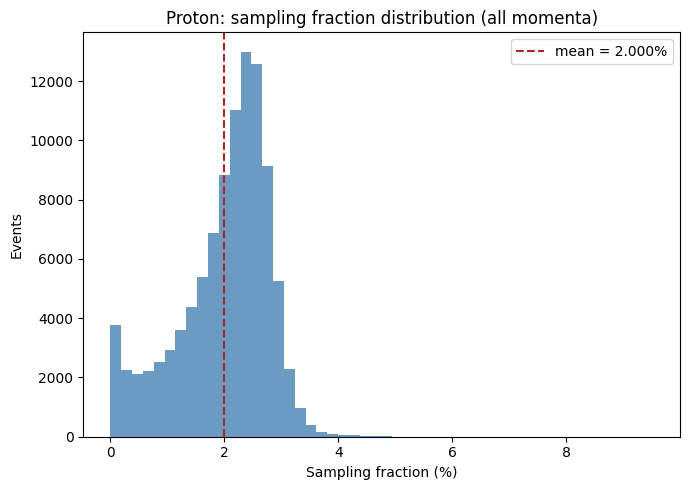

Proton (all momenta): mean sampling fraction = 1.9999%, std = 0.7987%, n_events = 100000
Proton (all momenta): scaling factor (1 / sampling fraction) = 50.0026


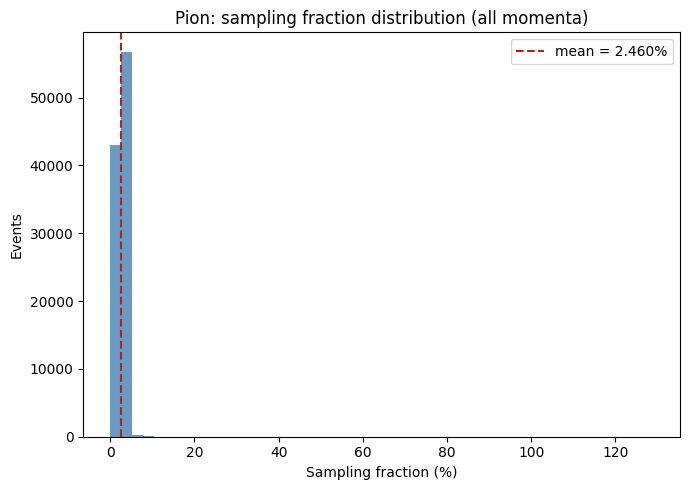

Pion (all momenta): mean sampling fraction = 2.4597%, std = 1.0059%, n_events = 100000
Pion (all momenta): scaling factor (1 / sampling fraction) = 40.6558


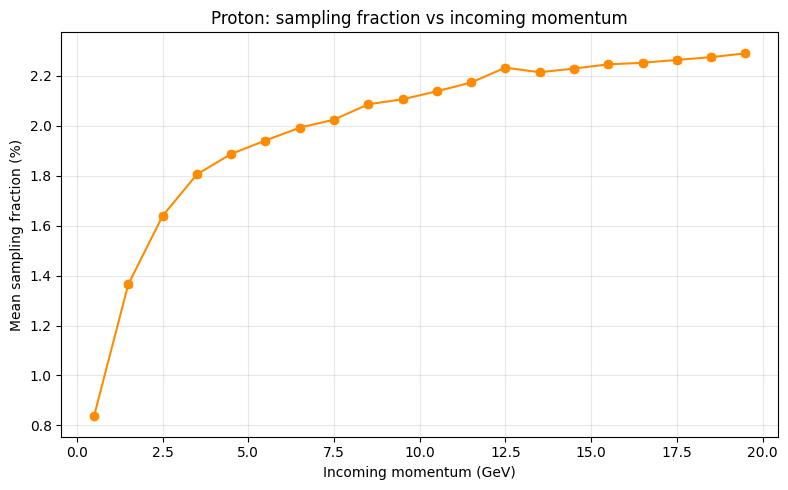

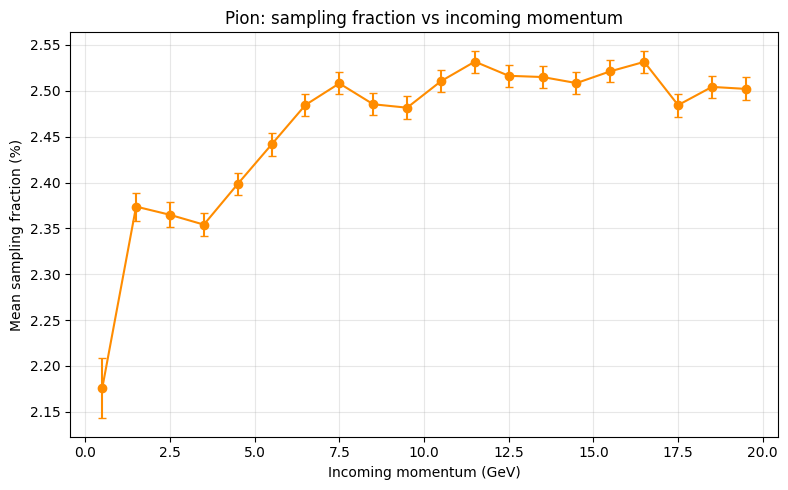

,momentum_bin,mean,std,count,bin_center,scaling_factor
0,"(0.0, 1.0]",0.021755,0.023130,5000,0.5,45.966528
1,"(1.0, 2.0]",0.023737,0.010864,5000,1.5,42.127721
2,"(2.0, 3.0]",0.023648,0.009495,5000,2.5,42.287176
3,"(3.0, 4.0]",0.023541,0.008947,5000,3.5,42.479883
4,"(4.0, 5.0]",0.023984,0.008695,5000,4.5,41.695044
5,"(5.0, 6.0]",0.024415,0.008736,5000,5.5,40.958778
6,"(6.0, 7.0]",0.024846,0.008376,5000,6.5,40.247897
7,"(7.0, 8.0]",0.025081,0.008551,5000,7.5,39.870718
8,"(8.0, 9.0]",0.024854,0.008642,5000,8.5,40.235741
9,"(9.0, 10.0]",0.024816,0.008669,5000,9.5,40.296558


In [5]:
plot_sampling_fraction_distribution(df_standalone_proton_s1, "Proton")
plot_sampling_fraction_distribution(df_standalone_pion_s1, "Pion")

sampling_fraction_vs_momentum(df_standalone_proton_s1, "Proton")
sampling_fraction_vs_momentum(df_standalone_pion_s1, "Pion")

Tamas' style plots, responses for different types of particles as a function of energy

In [6]:
#@ Tamas' style plots = Response for particles as a function of energy

from scipy.optimize import curve_fit
from scipy.stats import chi2 as chi2_dist


def gaussian(x, const, mean, sigma):
    return const * np.exp(-0.5 * ((x - mean) / sigma) ** 2)


def fit_total_visible_energy(df, momentum_center, momentum_half_width=0.5, bins=50):
    """
    Selects events near a given incoming momentum, histograms their total
    deposited energy per event, and fits a Gaussian to it
    """
    event_totals = compute_sampling_fraction(df)
    sel = event_totals[
        (event_totals['incoming_momentum'] >= momentum_center - momentum_half_width) &
        (event_totals['incoming_momentum'] < momentum_center + momentum_half_width)
    ]
    energies = sel['visible_energy'].to_numpy()

    counts, edges = np.histogram(energies, bins=bins)
    centers = 0.5 * (edges[:-1] + edges[1:])

    p0 = [counts.max(), energies.mean(), energies.std()]
    popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    const_fit, mean_fit, sigma_fit = popt
    const_err, mean_err, sigma_err = perr

    expected = gaussian(centers, *popt)
    mask = expected > 1e-9
    chi2_val = np.sum((counts[mask] - expected[mask]) ** 2 / expected[mask])
    ndf = mask.sum() - 3
    prob = 1 - chi2_dist.cdf(chi2_val, ndf) if ndf > 0 else np.nan

    stats = {
        'entries': len(energies), 'mean': energies.mean(), 'std_dev': energies.std(),
        'chi2': chi2_val, 'ndf': ndf, 'prob': prob,
        'constant': const_fit, 'constant_err': const_err,
        'fit_mean': mean_fit, 'fit_mean_err': mean_err,
        'fit_sigma': sigma_fit, 'fit_sigma_err': sigma_err,
    }
    return centers, counts, edges, popt, stats


def plot_total_visible_energy_grid(df, particle_label, momentum_centers=(1, 2, 5, 10, 15, 19),
                                    momentum_half_width=0.5, bins=50, ncols=3):
    nrows = int(np.ceil(len(momentum_centers) / ncols))
    fig, axes = robi.core.plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.2 * nrows))
    axes_flat = np.atleast_1d(axes).flatten()

    for i, p_center in enumerate(momentum_centers):
        ax = axes_flat[i]
        centers, counts, edges, popt, stats = fit_total_visible_energy(
            df, p_center, momentum_half_width=momentum_half_width, bins=bins)

        ax.bar(centers, counts, width=(edges[1] - edges[0]), color='white',
               edgecolor='#5b8dd6', linewidth=0.8)

        x_smooth = np.linspace(edges[0], edges[-1], 300)
        ax.plot(x_smooth, gaussian(x_smooth, *popt), color='red', linewidth=1.2)

        ax.set_title(f'Total visible energy ({particle_label}, {p_center} GeV)', fontsize=10)
        ax.set_xlabel('Energy (GeV)', fontsize=9)
        ax.set_ylabel('Number of events', fontsize=9)
        ax.tick_params(labelsize=8)

        stats_text = (
            f"Entries   {stats['entries']}\n"
            f"Mean      {stats['mean']:.5f}\n"
            f"Std Dev   {stats['std_dev']:.5f}\n"
            f"$\\chi^2$/ndf   {stats['chi2']:.1f} / {stats['ndf']}\n"
            f"Prob      {stats['prob']:.3f}\n"
            f"Constant  {stats['constant']:.1f} $\\pm$ {stats['constant_err']:.1f}\n"
            f"Mean      {stats['fit_mean']:.5f} $\\pm$ {stats['fit_mean_err']:.5f}\n"
            f"Sigma     {stats['fit_sigma']:.5f} $\\pm$ {stats['fit_sigma_err']:.5f}"
        )
        ax.text(0.97, 0.95, stats_text, transform=ax.transAxes, fontsize=6.5,
                va='top', ha='right', family='monospace',
                bbox=dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=0.6))

    for j in range(len(momentum_centers), len(axes_flat)):
        axes_flat[j].axis('off')

    robi.core.plt.suptitle(f'Response for {particle_label} as a function of energy', fontsize=14, y=1.02)
    robi.core.plt.tight_layout()
    robi.core.plt.show()

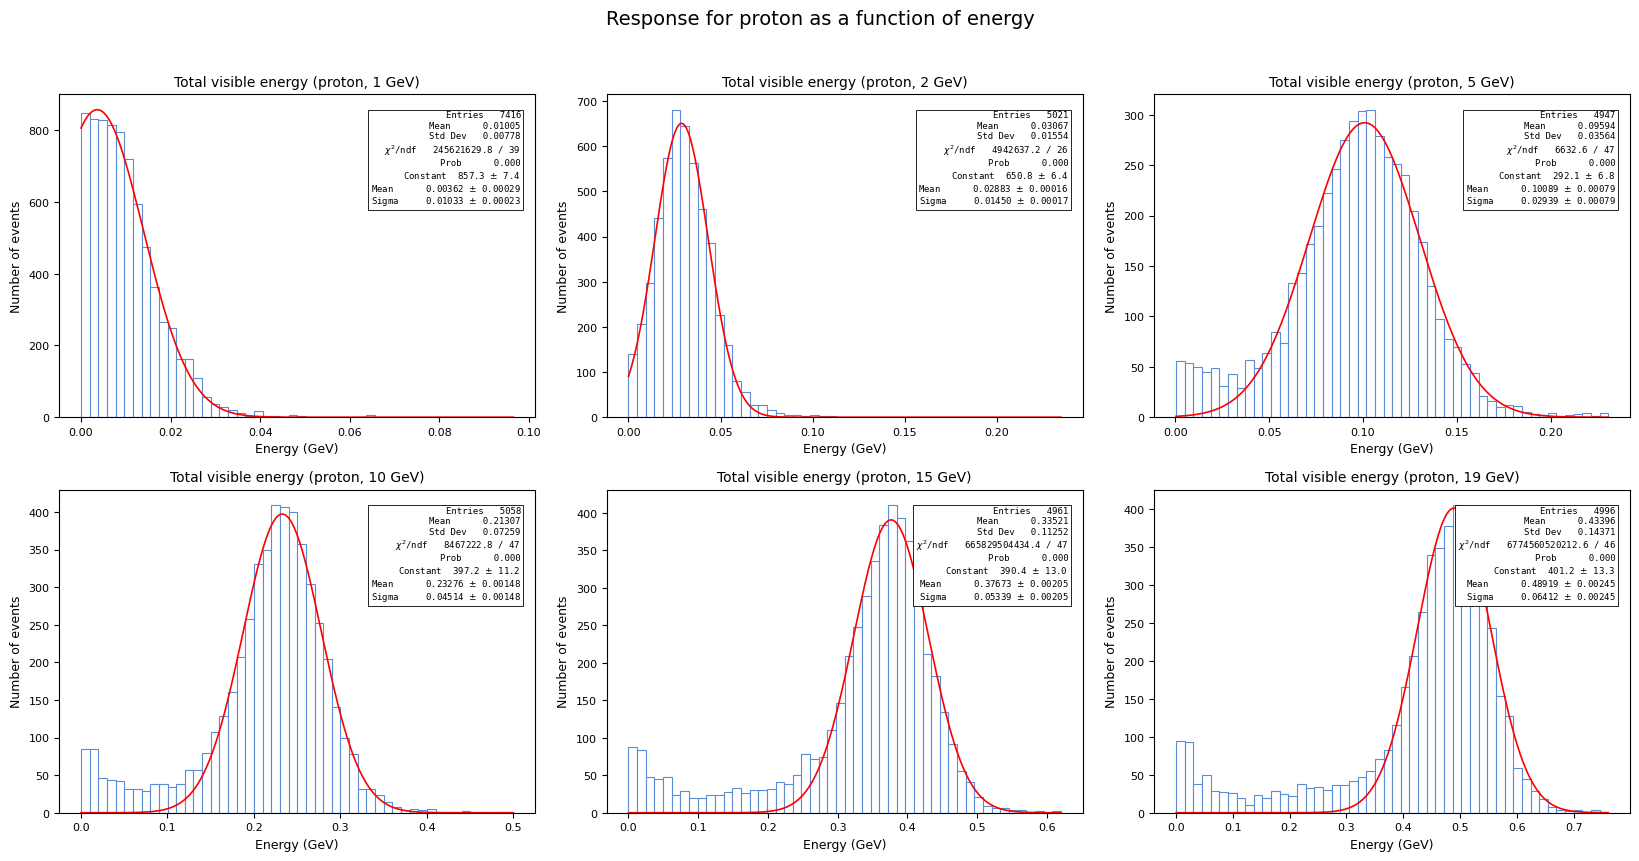

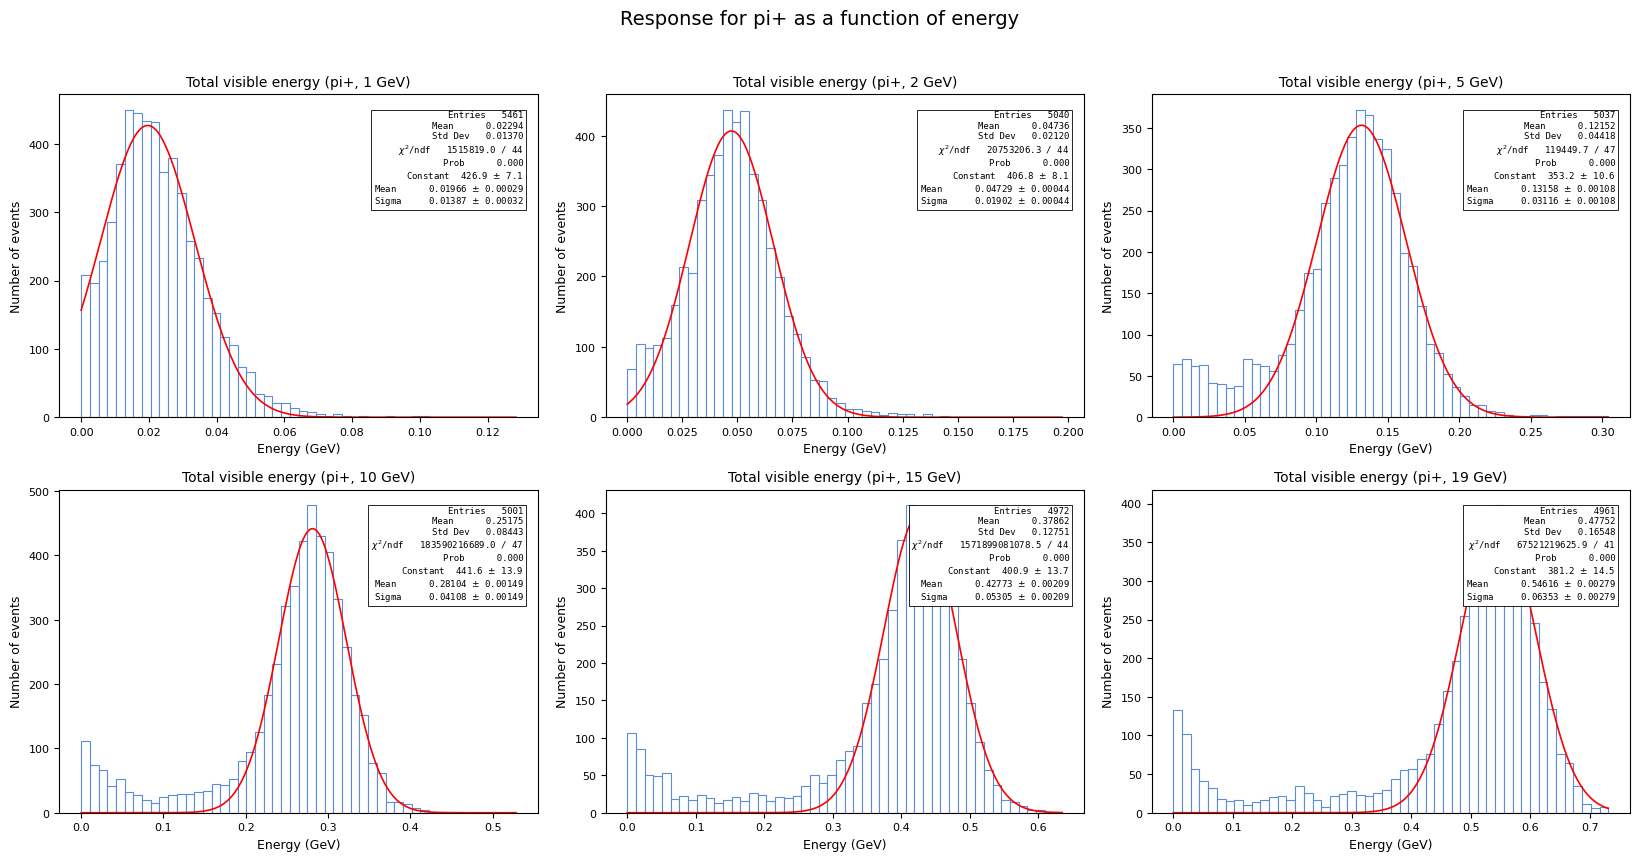

In [7]:
plot_total_visible_energy_grid(df_standalone_proton_s1, "proton", momentum_centers=(1, 2, 5, 10, 15, 19))
plot_total_visible_energy_grid(df_standalone_pion_s1, "pi+", momentum_centers=(1, 2, 5, 10, 15, 19))